# Representação Semântica de Frases com Embeddings

##### Quatro frases, as duas primeiras falam do mesmo assunto, comer macarrão, e as duas últimas mudam o assunto, falam da bolsa de valores.

### Geração de Embeddings

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sentence_transformers import SentenceTransformer
from networkx.algorithms.community import greedy_modularity_communities
from sklearn.manifold import TSNE

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

sentences = [
    "Você já comeu macarrão?",
    "Amo comer macarrão",
    "A bolsa de valores caiu",
    "Sim, eu vi que a bolsa de valores caiu, fiquei preocupado"
]


model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
S = model.encode(sentences)

print("\nEmbeddings (S):")
print(S.shape)  
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sofia\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00


Embeddings (S):
(4, 384)
[[ 0.13641723 -0.43722022 -0.07113042 ...  0.03691885 -0.33656225
  -0.04504834]
 [-0.04268571 -0.5354026  -0.0797546  ... -0.04431797 -0.17078304
  -0.12221889]
 [-0.12017221 -0.2324116   0.29484698 ... -0.33247417 -0.3116348
   0.17373067]
 [ 0.11363162 -0.18023111  0.16390264 ... -0.26072717 -0.26679808
  -0.11705965]]


### Construção da Matriz de Adjacência

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         0.        ]
 [0.75288379 0.         0.         0.        ]
 [0.09626053 0.08970934 0.         0.        ]
 [0.27125829 0.1494948  0.76192617 0.        ]]


### Grafo

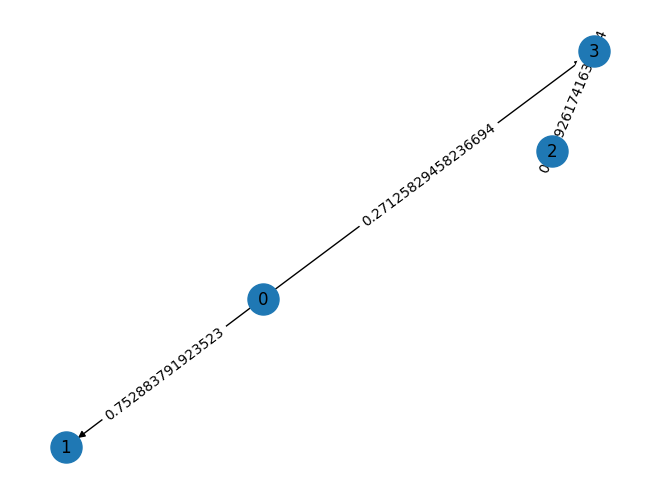

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences):
    G.add_node(i, label=s)

for i in range(4):
    for j in range(4):
        weight = A[i, j]
        if weight > 0.2:  
            G.add_edge(j, i, weight=weight) 

pos = nx.spring_layout(G)

nx.draw(G, pos, with_labels=True, node_size=500)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.show()

Você já comeu macarrão? → Cluster 0
Amo comer macarrão → Cluster 0
A bolsa de valores caiu → Cluster 1
Sim, eu vi que a bolsa de valores caiu, fiquei preocupado → Cluster 1


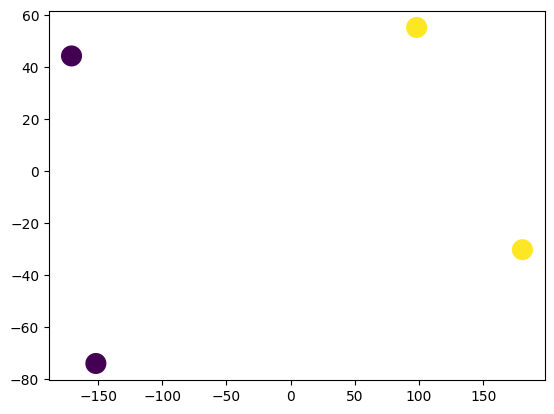

In [9]:
from sklearn.cluster import SpectralClustering

tsne = TSNE(n_components=2, random_state=0, perplexity=2)
S_2d = tsne.fit_transform(S)

similarity = S @ S.T

clustering = SpectralClustering(
    n_clusters=2,
    affinity='precomputed', 
    random_state=0
)

labels = clustering.fit_predict(similarity)

for i, s in enumerate(sentences):
    print(f"{s} → Cluster {labels[i]}")


plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=200)